In [11]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score,accuracy_score,recall_score,f1_score, roc_auc_score

In [2]:
%pip install seaborn

In [4]:
data = load_breast_cancer()

In [5]:
X = data.data
y = data.target

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state = 42, test_size = 0.2)

In [9]:
models = {
    "Linear SVM": SVC(kernel='linear'),
    "Polynomial_SVM": SVC(kernel='poly', degree = 3),
    "RBF_SVM": SVC(kernel='rbf')
}

In [10]:
for name, model in models.items():
    
    model.fit(X_train,y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    TP,TN, FP, FN = cm.ravel()

    print("\n", name)
    print("Confusion Matrix:\n", cm)

    print("Accuracy Score:", accuracy_score(y_test,y_pred))
    print("Precision Score:", precision_score(y_test, y_pred))
    print("Recall Score:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))
    print("ROU AUC", model.decision_function(X_test))


 Linear SVM
Confusion Matrix:
 [[39  4]
 [ 1 70]]
Accuracy Score: 0.956140350877193
Precision Score: 0.9459459459459459
Recall Score: 0.9859154929577465
F1 Score: 0.9655172413793104
ROU AUC [  0.9310456   -9.01245538  -3.23848284   3.98354133   5.04532352
 -12.08830448 -13.50924051  -2.08883758   2.07957553   2.79737323
   1.41272208  -3.44775151   2.68697933  -1.18200629   3.46784989
  -2.46465052   3.57362299   6.21801899   6.04186516  -8.33381938
   1.07458647   2.99536201 -10.8060434    3.77370141   3.09373226
   4.57463831   3.48552277   3.47942426   3.02636106  -9.63531094
   3.15892149   4.29985992   3.16563668   2.41490058   4.32933762
   3.25899752  -2.73806809   3.54729804  -5.68627327   0.5023176
   4.20788169  -3.91516008   3.57748948   2.65234461   4.78704781
   1.52776459   4.59304903   4.2760999    1.19623902   3.70102504
  -4.72817123 -10.72875033   0.70121404   5.5206976    3.63040437
   2.12978411   4.1752838  -15.60338787   0.16341643   4.60894714
   2.3539473   -8.

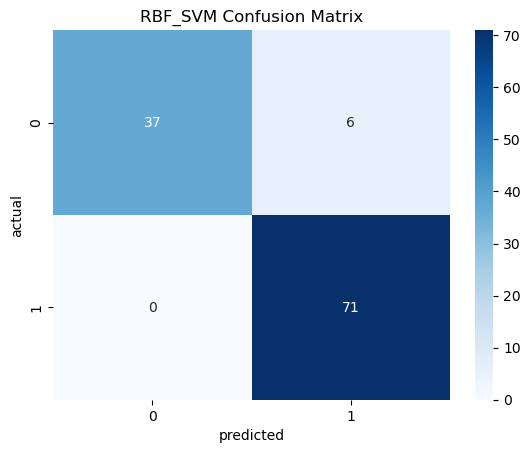

In [12]:
sns.heatmap(cm, annot=True, cmap='Blues')
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title(name + " Confusion Matrix")
plt.show()